# 03 | Local injury, distributed graphs and SC–FC coupling

**Question:** how much do conclusions depend on graph construction?

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


In [2]:
policy=json.loads((RESULTS/"primary_sc/policy.json").read_text())
display(pd.DataFrame(policy["sessions"]).T)
display(Image(filename=str(RESULTS/"figures/primary_sc_choice.png")))
sc_sensitivity=pd.read_csv(RESULTS/"primary_sc/coupling_sensitivity.csv")
def compare_sc(design="consensus80_k1",support="common"):
    display(sc_sensitivity[(sc_sensitivity.design==design)&(sc_sensitivity.support==support)])
    gs=pd.read_csv(RESULTS/"primary_sc/graph_sensitivity.csv")
    display(gs[(gs.design==design)&(gs.support==support)&(gs.target_density==.2)])
widgets.interact(compare_sc,design=widgets.Dropdown(options=list(dict.fromkeys(sc_sensitivity.design)),value="consensus80_k1"),support=widgets.Dropdown(options=["common","own"],value="common"))

,design,support,coupling_role,structural_role,pre_edges,post_edges,shared_edges,union_edges,primary_pre,primary_post,primary_delta,strict_pre,strict_post,strict_delta,reversal_shift
40,consensus80_k1,common,primary,sensitivity,823,823,823,823,0.188216,0.146488,-0.041728,0.160765,0.126526,-0.034239,0.007489


,design,support,coupling_role,structural_role,session,target_density,nodes,edges,density,components,largest_component,binary_global_efficiency,weighted_global_efficiency,weighted_clustering,mean_strength,weight_scale
402,consensus80_k1,common,primary,sensitivity,preop,0.2,100,823,0.166263,1,100,0.53133,0.046194,0.019597,93.214667,101.7
407,consensus80_k1,common,primary,sensitivity,postop,0.2,100,823,0.166263,1,100,0.53133,0.043717,0.019804,90.715333,101.7


interactive(children=(Dropdown(description='design', index=9, options=('original_fraction', 'original_k1', 'or…

<function __main__.compare_sc(design='consensus80_k1', support='common')>

## Why two related supports?
Own consensus describes changing reconstructed topology, preserving 337/340 session-specific consensus connections. Common consensus asks how SC/FC ranks change on the **same connections**; it excludes those connections and uses both scans to define the population. Neither estimates axonal loss. Do not compare an own-support graph with a common-support coupling value as if they described identical edges.

All-run mean counts include misses, avoiding a detected-only mean. Per-seed rates avoid a session-total compositional constraint, but seed-mask size and tracking yield still differ. Multiplication by a positive scalar preserves Spearman ranks; session-specific normalization can alter weighted graph comparisons. No ACT/SIFT2 or biological calibration is implied. Compare original fractions, unfiltered mean counts, higher count cutoffs and 50/95/100% consensus above. The original fraction normalization is defined on assigned interparcel streamlines, whereas primary rates use attempted seeds.

## Keep node identity fixed
There are 100 Schaefer cortical parcels and 7 atlas network labels (Vis, SomMot, DorsAttn, SalVentAttn, Limbic, Cont, Default). Group-atlas labels are anatomical hypotheses in this patient, not individually validated functional networks. FC comparisons use the intersection of valid nodes in both sessions. SC and FC use the same identity table; subcortical and cerebellar pathways are omitted.

For weighted graph paths, edge cost is $\ell_{ij}=1/w_{ij}$ and efficiency is $E=[n(n-1)]^{-1}\sum_{i\ne j}1/d_{ij}$; disconnected pairs contribute zero. We threshold positive edges over requested densities 0.10–0.30 and save the **achieved** density. SC efficiency uses one shared maximum-weight scale across sessions. FC uses positive edges at fixed scale 1; signed matrices remain available separately.

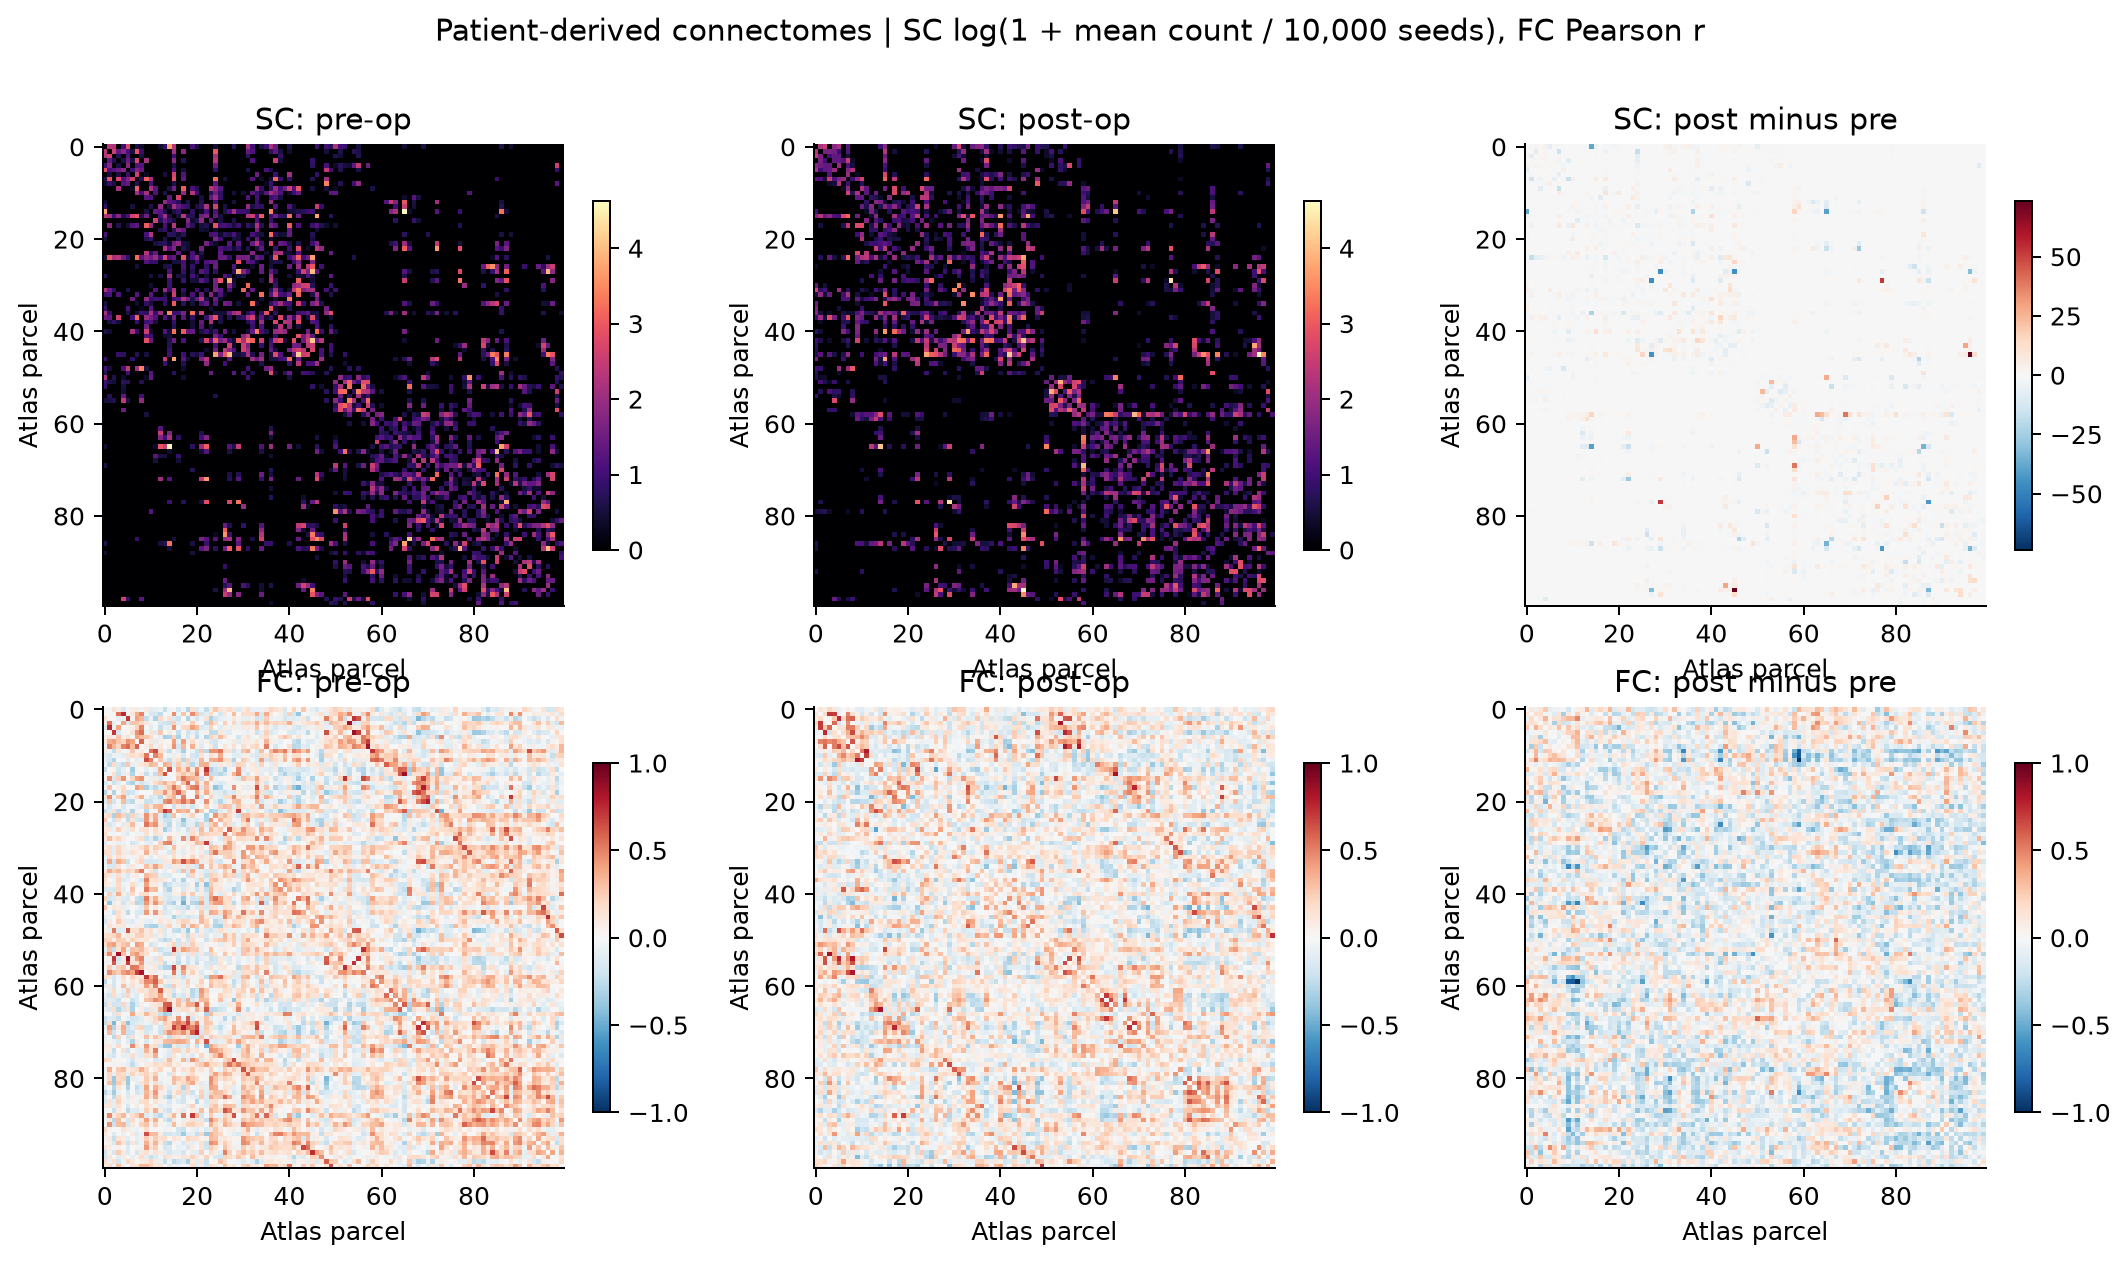

,session,modality,target_density,nodes,edges,density,components,largest_component,binary_global_efficiency,weighted_global_efficiency,weighted_clustering,mean_strength,weight_scale
4,preop,SC,0.2,100,990,0.2,1,100,0.568670,0.048060,0.018686,103.280333,101.7
5,preop,FC_positive,0.2,100,990,0.2,1,100,0.557879,0.213575,0.199240,7.460088,1.0
14,postop,SC,0.2,100,990,0.2,1,100,0.571313,0.045123,0.019050,99.986333,101.7
15,postop,FC_positive,0.2,100,990,0.2,1,100,0.573754,0.193583,0.151840,6.509051,1.0


In [3]:
display(Image(filename=str(RESULTS/"figures/connectomes.png")))
display(pd.read_csv(RESULTS/"graph_metrics.csv").query("target_density==0.2"))

In [4]:
from pat16.networks import metrics

def inspect_graph(modality="SC",density=.2):
    common=np.load(RESULTS/"common_fc_nodes.npy");rows=[]
    scs=[load_weights(session) for session in SESSIONS];scale=max(w.max() for w in scs)
    for session in SESSIONS:
        w=load_weights(session) if modality=="SC" else np.load(RESULTS/session/"fc_primary.npy")
        if modality=="FC":w=np.maximum(w[np.ix_(common,common)],0)
        rows.append(dict(session=session,**metrics(w,density,scale if modality=="SC" else 1)))
    display(pd.DataFrame(rows))
widgets.interact(inspect_graph,modality=widgets.Dropdown(options=["SC","FC"]),density=widgets.FloatSlider(min=.05,max=.4,step=.05,value=.2))

,session,nodes,edges,density,components,largest_component,binary_global_efficiency,weighted_global_efficiency,weighted_clustering,mean_strength,weight_scale
0,preop,100,990,0.2,1,100,0.568670,0.048060,0.018686,103.280333,101.7
1,postop,100,990,0.2,1,100,0.571313,0.045123,0.019050,99.986333,101.7


interactive(children=(Dropdown(description='modality', options=('SC', 'FC'), value='SC'), FloatSlider(value=0.…

<function __main__.inspect_graph(modality='SC', density=0.2)>

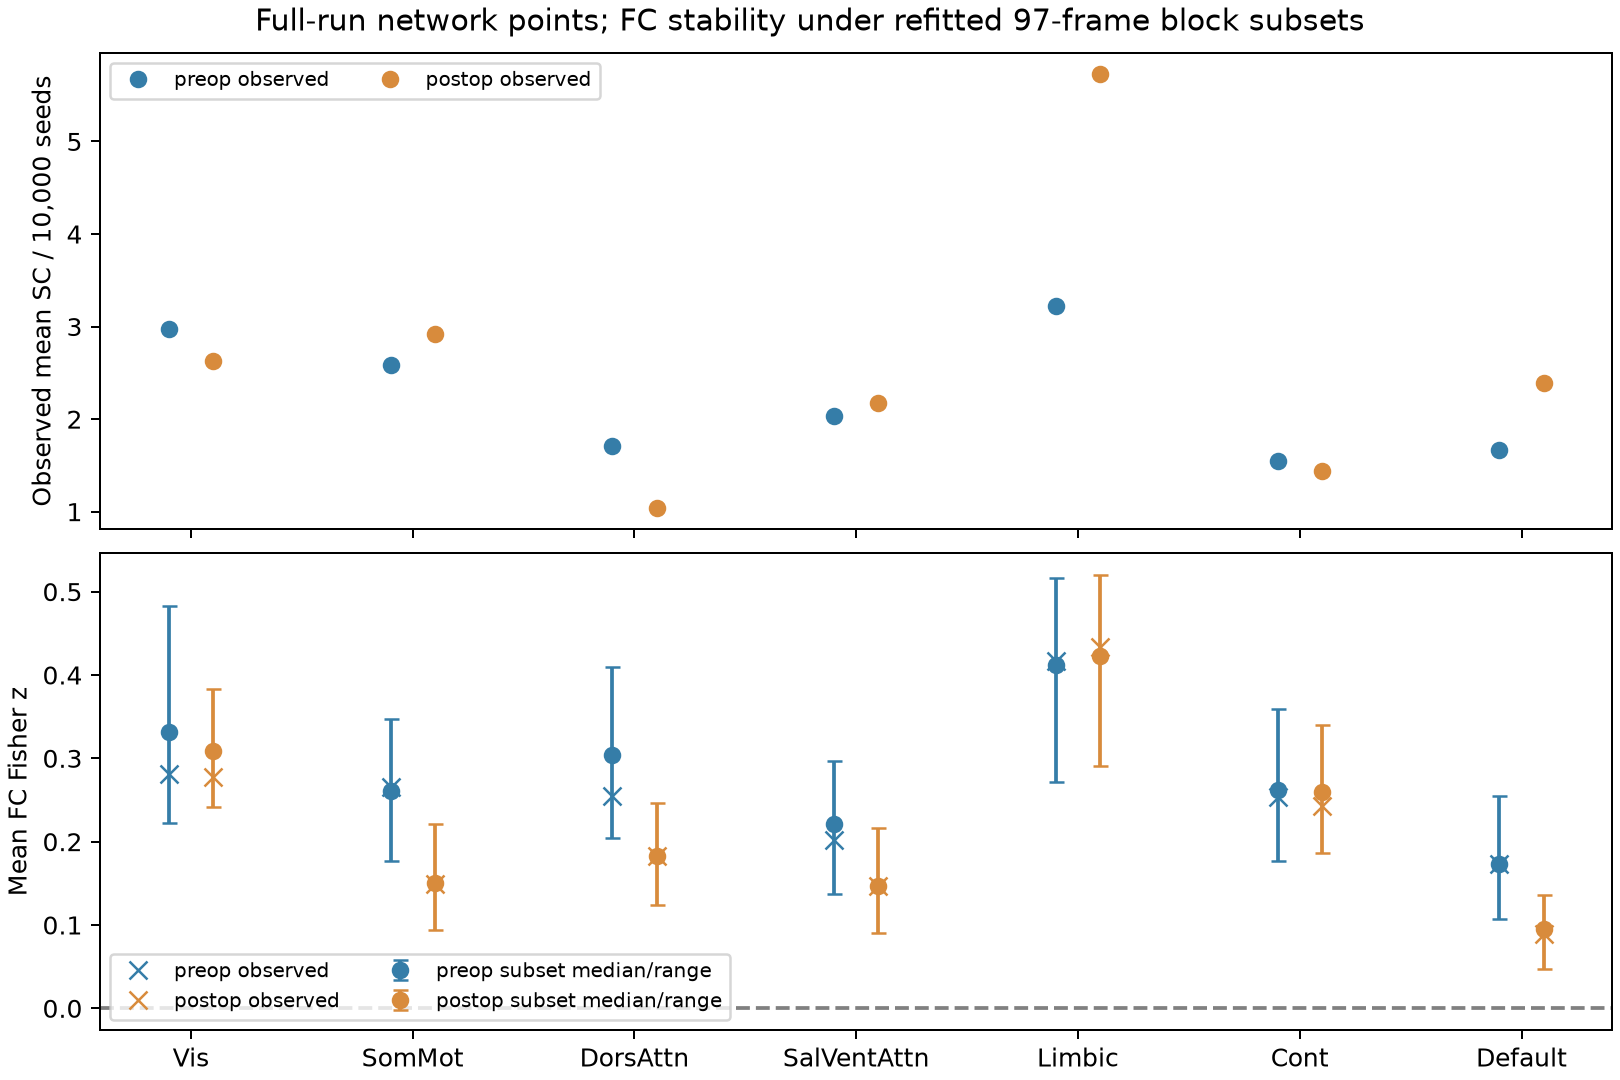

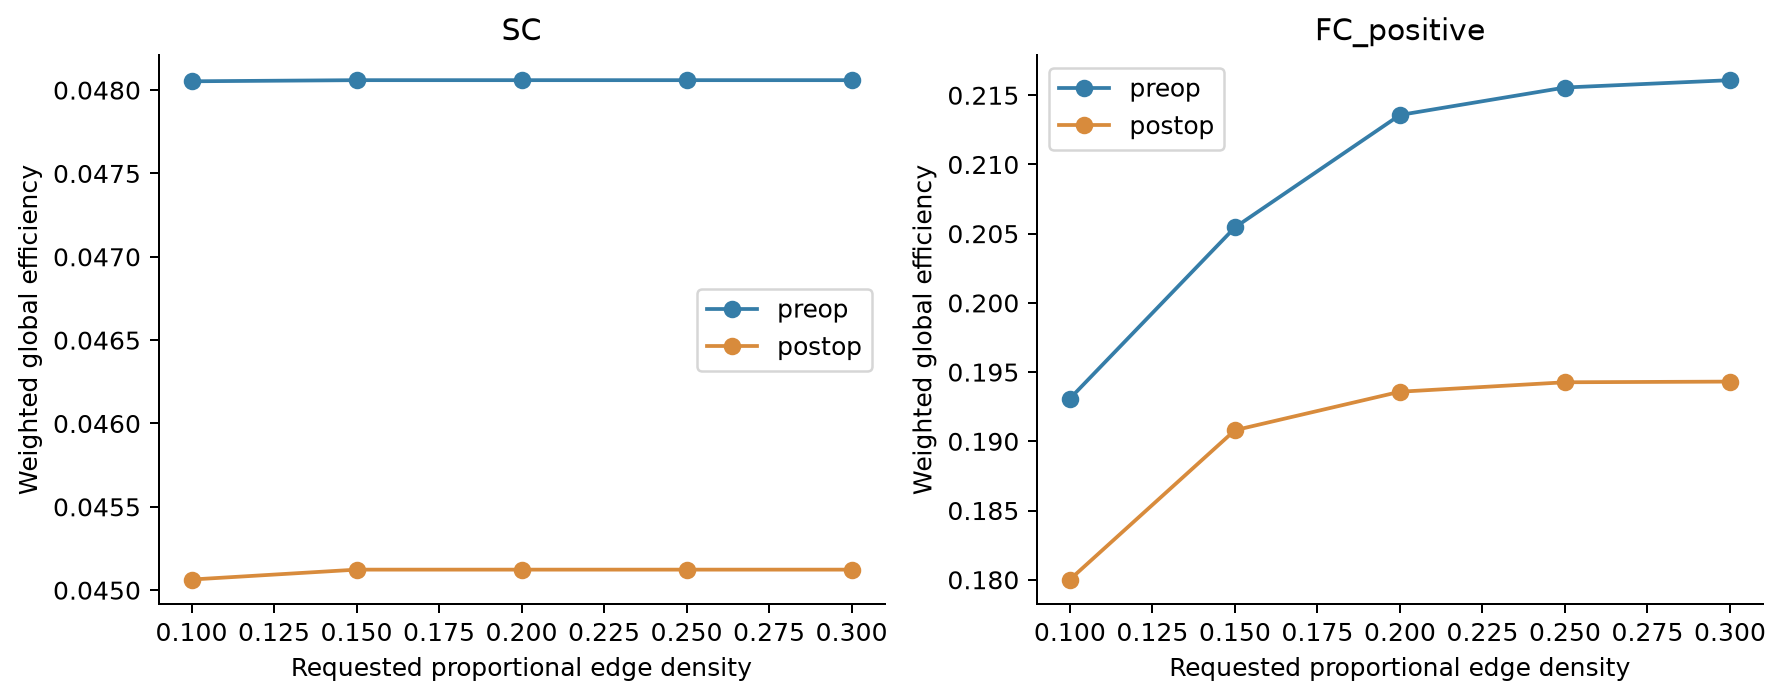

preop descriptive SC–FC Spearman rho: 0.1882158540968531
postop descriptive SC–FC Spearman rho: 0.14648812690454752


In [5]:
display(Image(filename=str(RESULTS/"figures/primary_fc_network_sessions.png")))
display(Image(filename=str(RESULTS/"figures/threshold_sensitivity.png")))
for session in SESSIONS: print(session,"descriptive SC–FC Spearman rho:",summary["sessions"][session]["sc_fc_spearman"])

In [6]:
# Same SC, nodes, corrected cortical signals and censoring; alternative nuisance models.
denoising_models=pd.read_csv(RESULTS/"primary_sc/denoising_comparison.csv")
display(denoising_models.query("BOLD_processing=='corrected'")[["session","model","mean_fc_r","sc_fc_spearman","weighted_global_efficiency","residual_df"]])
print("SC–FC coupling and FC graph efficiency remain model-dependent; see notebook 06.")

,session,model,mean_fc_r,sc_fc_spearman,weighted_global_efficiency,residual_df
6,preop,motion_dct,0.404341,0.101433,0.335300,112
7,preop,original5,0.359665,0.146589,0.310866,107
8,preop,anatomical5_raw,0.111746,0.189120,0.225258,107
9,preop,anatomical5,0.087228,0.188216,0.213575,107
10,preop,wm5_csf5,0.049265,0.221017,0.189601,102
11,preop,wm_csf_means,0.077837,0.140382,0.224928,110
18,postop,motion_dct,0.289407,0.109654,0.299794,116
19,postop,original5,0.133487,0.142356,0.229351,111
20,postop,anatomical5_raw,0.049493,0.133122,0.193697,111
21,postop,anatomical5,0.045607,0.146488,0.193583,111


SC–FC coupling and FC graph efficiency remain model-dependent; see notebook 06.


## SC–FC coupling is a property of edges
We compute Spearman correlation between log(1+SC) and FC over the same 823 common-consensus upper-triangle edges in the common finite-FC node set, with session-specific repeat-mean weights. Spatial distance and atlas effects can influence this statistic. Edges are dependent, so no naïve edgewise p-value is reported. Notebook [07](07_censoring_motion_duration_and_coupling.ipynb) shows that strict censoring, frame matching and refitting change the contrast, and that the SC edge support/reference also matters. Its direction remains unresolved; the primary fit stays fixed. Notebook [08](08_edges_networks_and_coupling_reversal.ipynb) separates shared/session-specific SC edge terms, network pairs and reranked deletion effects. Notebook [09](09_structural_edge_reliability.ipynb) shows that repeated seeding, count cutoffs and consensus support further change the coupling population; historical seed-160 results remain labelled sensitivities.

**Exercise:** contrast unthresholded matrices with thresholded graph efficiency. Can a graph appear more efficient because weak edges were removed or weights renormalized? How does a shared scale differ from independently scaling each session to its own strongest edge? Do not treat node/edge counts as independent biological observations.